# Predicting Brain Responses From Movies
Can a multimodal model (video + audio + text) predict fMRI activity, and does letting each brain region pick its own modality and time lag help?

**Data note:** the official Algonauts 2025 data is access-gated and can't be downloaded on Windows, so this notebook generates a **synthetic** stand-in with the same shape (4 subjects, TR = 1.49 s, train/val/test/OOD splits). Results are for the pipeline, not real brains.

In [1]:
import copy, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

SEED = 42
SUBJECTS = ['sub-01', 'sub-02', 'sub-03', 'sub-05']
P, T = 200, 90                      # parcels, TRs per segment
SPLITS = {'train': 24, 'val': 4, 'test': 4, 'ood': 4}
DV, DA, DT = 64, 48, 32             # video / audio / text feature sizes
EPOCHS, ABL_EPOCHS = 40, 20
TR = 1.49

## 1. Synthetic data
Every brain parcel gets a hidden recipe: how much it uses video/audio/text, and its own delay. The models never see it; we only use it at the end to check what they learned.

In [2]:
def smooth_walk(n, dim, rng, s):
    e = rng.normal(size=(n, dim)); out = np.zeros((n, dim), dtype=np.float32); out[0] = e[0]
    for t in range(1, n):
        out[t] = s * out[t - 1] + np.sqrt(1 - s ** 2) * e[t]
    return out

def shift(x, k):                    # delay x by k TRs
    if k > 0: return np.concatenate([np.repeat(x[:1], k, 0), x[:-k]])
    if k < 0: return np.concatenate([x[-k:], np.repeat(x[-1:], -k, 0)])
    return x

def make_latents(rng, ood):         # hidden video/audio/text signals; OOD = faster, more coupled
    s, c = (0.7, 0.65) if ood else (0.85, 0.35)
    z = smooth_walk(T, 6, rng, s)
    priv = [smooth_walk(T, d, rng, sm) for d, sm in ((16, s), (12, s), (8, max(s - 0.1, 0.4)))]
    proj = [rng.normal(size=(6, d)) for d in (16, 12, 8)]
    return [((1 - c) * p + c * (z @ w)).astype(np.float32) for p, w in zip(priv, proj)]

def render_video(lat, rng, fps=4, hw=8):
    base = (lat @ rng.normal(scale=0.6, size=(16, hw * hw * 3))).reshape(T, hw, hw, 3)
    fr = np.repeat(base[:, None], fps, axis=1)
    fr = fr + rng.normal(scale=0.35, size=fr.shape)
    return (fr + np.linspace(-0.15, 0.15, fps)[None, :, None, None, None] * rng.normal(scale=0.2, size=(1, 1, hw, hw, 3))).astype(np.float32)

def render_audio(lat, rng, n=32):
    t = np.linspace(0, 1, n, endpoint=False)
    freqs, amps = 2 + 6 / (1 + np.exp(-lat[:, :4])), 0.5 + 0.5 * np.tanh(lat[:, 4:8])
    wave = sum(amps[:, k, None] * np.sin(2 * np.pi * freqs[:, k, None] * t) for k in range(4))
    return (wave + rng.normal(scale=0.25, size=wave.shape)).astype(np.float32)

def render_text(lat, rng, vocab=512, words=3, topics=8):
    logits = lat @ rng.normal(size=(8, topics))
    pr = np.exp(logits - logits.max(1, keepdims=True)); pr /= pr.sum(1, keepdims=True)
    tw = rng.dirichlet(np.full(vocab, 0.08), size=topics)
    return np.stack([rng.choice(vocab, size=words, p=tw[rng.choice(topics, p=p)]) for p in pr])

def make_truth(rng):                # per-parcel modality weights, delay, readout
    alpha = np.array([[8, 1, 1], [1, 8, 1], [1, 1, 8], [2.5, 2.5, 2.5]])[rng.integers(0, 4, size=P)]
    mix = np.array([rng.dirichlet(a) for a in alpha], dtype=np.float32)
    lag = rng.integers(2, 7, size=P)
    proj = [rng.normal(scale=1 / np.sqrt(d), size=(P, d)) for d in (16, 12, 8)]
    return mix, lag, proj

def make_fmri(lat, mix, lag, proj, rng, noise):
    resp = np.zeros((T, P), dtype=np.float32)
    for p in range(P):
        s = [np.tanh(shift(l, lag[p]) @ pr[p]) for l, pr in zip(lat, proj)]
        resp[:, p] = mix[p, 0] * s[0] + mix[p, 1] * s[1] + mix[p, 2] * s[2]
    basis, load = rng.normal(size=(T, 5)), rng.normal(size=(5, P)) / np.sqrt(5)
    return (resp + noise * (0.5 * basis @ load + 0.5 * rng.normal(size=(T, P)))).astype(np.float32)

## 2. Feature extraction
Raw frames, waveforms and word ids become one small vector per TR.

In [3]:
def project(x, out, seed):
    return x @ np.random.default_rng(seed).normal(scale=1 / np.sqrt(x.shape[-1]), size=(x.shape[-1], out))

def video_feats(v):                 # color stats, motion, edges, coarse layout
    f = np.concatenate([v.mean((1, 2, 3)), v.std((1, 2, 3)),
                        np.abs(np.diff(v, axis=1)).mean((1, 2, 3, 4))[:, None],
                        (np.abs(np.diff(v, axis=2)).mean((1, 2, 3, 4)) + np.abs(np.diff(v, axis=3)).mean((1, 2, 3, 4)))[:, None],
                        v.mean(1)[:, ::2, ::2].reshape(len(v), -1)], 1)
    return project(f, DV, 101).astype(np.float32)

def audio_feats(a):                 # energy, zero-crossings, spectrum, centroid, bandwidth
    spec, freqs = np.abs(np.fft.rfft(a, axis=1)), np.fft.rfftfreq(a.shape[1])
    edges = np.linspace(0, spec.shape[1], 9).astype(int)
    binned = np.stack([spec[:, edges[i]:edges[i + 1]].mean(1) for i in range(8)], 1)
    cen = (spec * freqs).sum(1) / (spec.sum(1) + 1e-8)
    bw = np.sqrt(((freqs - cen[:, None]) ** 2 * spec).sum(1) / (spec.sum(1) + 1e-8))
    f = np.concatenate([(a ** 2).mean(1)[:, None], (np.diff(np.sign(a), axis=1) != 0).mean(1)[:, None], binned, cen[:, None], bw[:, None]], 1)
    return project(f, DA, 202).astype(np.float32)

def text_feats(tok):                # average word embedding per TR
    return np.random.default_rng(303).normal(scale=0.3, size=(512, DT))[tok].mean(1).astype(np.float32)

master = np.random.default_rng(SEED)
mix, lag_true, proj_true = make_truth(np.random.default_rng(master.integers(1 << 30)))
raw = {s: [] for s in SPLITS}       # per segment: video, audio, text features + fMRI of every subject
for split, n in SPLITS.items():
    for _ in range(n):
        rng = np.random.default_rng(master.integers(1 << 30))
        lat = make_latents(rng, split == 'ood')
        v, a, x = render_video(lat[0], rng), render_audio(lat[1], rng), render_text(lat[2], rng)
        fm = {}
        for i, sub in enumerate(SUBJECTS):
            srng = np.random.default_rng(master.integers(1 << 30))
            w = np.clip(mix + srng.normal(scale=0.05, size=mix.shape), 1e-3, None); w /= w.sum(1, keepdims=True)
            fm[sub] = make_fmri(lat, w, lag_true, proj_true, srng, 0.55 + 0.1 * i)
        raw[split].append((video_feats(v), audio_feats(a), text_feats(x), fm))
print({s: len(g) for s, g in raw.items()}, '| fMRI per segment:', raw['train'][0][3]['sub-01'].shape)

{'train': 24, 'val': 4, 'test': 4, 'ood': 4} | fMRI per segment: (90, 200)


## 3. Cleaning
Drop the first 2 TRs (scanner warm-up), clip outliers beyond 6 SD, z-score with **train-only** statistics, then optionally delay the stimulus by `lag` TRs.

In [4]:
def clip6(y):
    m, s = y.mean(0), y.std(0) + 1e-6
    return np.clip(y, m - 6 * s, m + 6 * s)

def prep(sub, lag=0):
    d = {s: {'v': np.stack([g[0][2:] for g in segs]), 'a': np.stack([g[1][2:] for g in segs]),
             'x': np.stack([g[2][2:] for g in segs]), 'y': np.stack([clip6(g[3][sub][2:]) for g in segs])}
         for s, segs in raw.items()}
    for k in 'vaxy':
        tr = d['train'][k].reshape(-1, d['train'][k].shape[-1]); mu, sd = tr.mean(0), tr.std(0) + 1e-6
        for s in d: d[s][k] = ((d[s][k] - mu) / sd).astype(np.float32)
    for s in d:
        for k in 'vax': d[s][k] = np.stack([shift(f, lag) for f in d[s][k]])
    return d

def pearson(y, p):                  # correlation per parcel (the official metric)
    y, p = y - y.mean(0), p - p.mean(0)
    return np.nan_to_num((y * p).sum(0) / np.sqrt((y ** 2).sum(0) * (p ** 2).sum(0) + 1e-12))

def features(d, s): return np.concatenate([d[s][k] for k in 'vax'], -1).reshape(-1, DV + DA + DT)

## 4. EDA (3 plots)

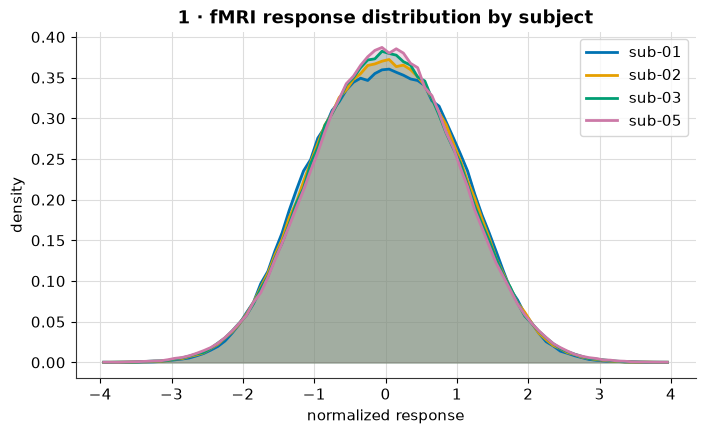

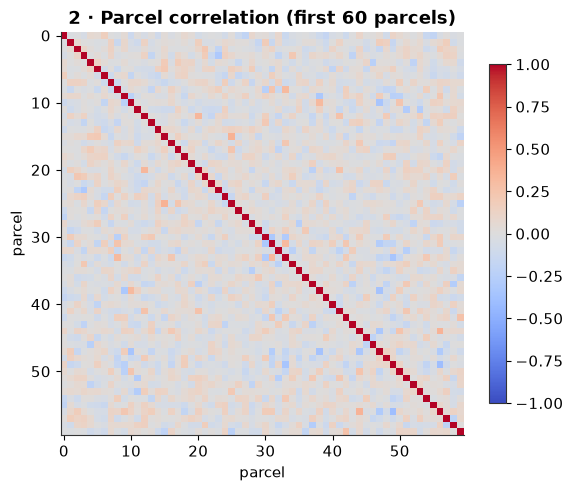

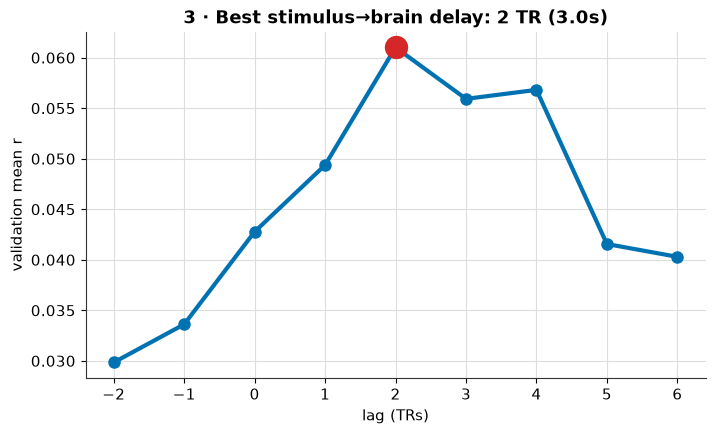

In [5]:
BG, ACC, GREY = '#ffffff', '#0072b2', '#8a8a8a'
COLORS = ['#0072b2', '#e69f00', '#009e73', '#cc79a7']
plt.rcParams.update({'figure.facecolor': BG, 'axes.facecolor': BG, 'axes.edgecolor': '#333', 'axes.grid': True, 'axes.axisbelow': True,
                     'grid.color': '#ddd', 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titleweight': 'bold', 'axes.titlesize': 13})

# plot 1: fMRI value distribution per subject
fig, ax = plt.subplots(figsize=(8, 4.5))
for sub, c in zip(SUBJECTS, COLORS):
    vals = prep(sub)['train']['y'].ravel()
    h, e = np.histogram(vals, bins=80, range=(-4, 4), density=True)
    ax.fill_between((e[1:] + e[:-1]) / 2, h, color=c, alpha=0.25); ax.plot((e[1:] + e[:-1]) / 2, h, color=c, label=sub, lw=2)
ax.set(title='1 · fMRI response distribution by subject', xlabel='normalized response', ylabel='density'); ax.legend()
plt.show()

# plot 2: parcel-to-parcel correlation
Ytr = prep('sub-01')['train']['y'].reshape(-1, P)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(np.corrcoef(Ytr[:, :60].T), cmap='coolwarm', vmin=-1, vmax=1); ax.grid(False)
ax.set(title='2 · Parcel correlation (first 60 parcels)', xlabel='parcel', ylabel='parcel'); fig.colorbar(im, shrink=0.8)
plt.show()

# plot 3: which stimulus delay predicts the brain best? (Ridge on train, scored on val)
lags = list(range(-2, 7)); lag_scores = []
for lag in lags:
    d = prep('sub-01', lag)
    m = Ridge(alpha=100).fit(features(d, 'train'), d['train']['y'].reshape(-1, P))
    lag_scores.append(pearson(d['val']['y'].reshape(-1, P), m.predict(features(d, 'val'))).mean())
best_lag = lags[int(np.argmax(lag_scores))]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lags, lag_scores, color=ACC, lw=3, marker='o', ms=8)
ax.scatter([best_lag], [max(lag_scores)], s=250, color='#d62728', zorder=5)
ax.set(title=f'3 · Best stimulus→brain delay: {best_lag} TR ({best_lag * TR:.1f}s)', xlabel='lag (TRs)', ylabel='validation mean r')
plt.show()

## 5. Models
Same data, same trainer, six models: **Ridge**, **Deep CCA**, **Perceiver**, **Mamba**, **Cross-Modal Transformer**, and the proposed **Hybrid** (each parcel learns its own modality weights and time lag).

In [6]:
D = prep('sub-01', best_lag)
Y = {s: D[s]['y'].reshape(-1, P) for s in D}
NTR = SPLITS['train']
rows, histories = [], {}

def record(name, params, ptest, pood, secs):
    r = pearson(Y['test'], ptest)
    rows.append(dict(model=name, params=params, test_r=r.mean(), test_median_r=np.median(r),
                     test_mse=((Y['test'] - ptest) ** 2).mean(), ood_r=pearson(Y['ood'], pood).mean(), secs=secs))
    print(f"{name:22s} test r={rows[-1]['test_r']:.4f}  ood r={rows[-1]['ood_r']:.4f}  ({secs:.0f}s, {params} params)")

def predict(model, split):
    model.eval()
    with torch.no_grad():
        return model(*[torch.tensor(D[split][k]) for k in 'vax']).numpy().reshape(-1, P)

def fit(model, epochs):
    np.random.seed(SEED)
    opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, wait, best_state, hist = -9, 0, None, []
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(NTR); total = 0; nb = 0
        for i in range(0, NTR, 8):
            v, a, x, y = [torch.tensor(D['train'][k][perm[i:i + 8]]) for k in 'vaxy']
            opt.zero_grad(); loss = F.mse_loss(model(v, a, x), y); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); total += loss.item(); nb += 1
        sched.step()
        pv = predict(model, 'val'); r = pearson(Y['val'], pv).mean()
        hist.append(dict(epoch=ep, train_loss=total / nb, val_loss=((pv - Y['val']) ** 2).mean(), val_r=r))
        if r > best: best, wait, best_state = r, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= 6: break
    model.load_state_dict(best_state)
    return hist

def run(name, model, epochs=EPOCHS):
    t0 = time.time(); histories[name] = fit(model, epochs)
    record(name, sum(p.numel() for p in model.parameters()), predict(model, 'test'), predict(model, 'ood'), time.time() - t0)

def best_ridge(Xtr, Ytr, Xva, Yva):    # pick alpha on validation
    return max((Ridge(alpha=a).fit(Xtr, Ytr) for a in (1, 10, 100, 1e3, 1e4)), key=lambda m: pearson(Yva, m.predict(Xva)).mean())

### Model 1 · Ridge (linear baseline)

In [7]:
t0 = time.time()
Xr = {s: features(D, s) for s in D}
ridge = best_ridge(Xr['train'], Y['train'], Xr['val'], Y['val'])
record('Ridge', Xr['train'].shape[1] * P, ridge.predict(Xr['test']), ridge.predict(Xr['ood']), time.time() - t0)

Ridge                  test r=0.0724  ood r=0.0159  (0s, 28800 params)


### Model 2 · Deep CCA
Three small networks learn a shared space that maximizes correlation between video, audio and text; Ridge then reads the brain from it.

In [8]:
def cca_loss(h1, h2, eps=1e-3):
    n, k = h1.shape; h1, h2 = h1 - h1.mean(0), h2 - h2.mean(0)
    s11 = h1.T @ h1 / (n - 1) + eps * torch.eye(k); s22 = h2.T @ h2 / (n - 1) + eps * torch.eye(k); s12 = h1.T @ h2 / (n - 1)
    def inv_sqrt(m):
        w, u = torch.linalg.eigh(m); return u @ torch.diag(w.clamp(min=1e-6) ** -0.5) @ u.T
    return -torch.linalg.svdvals(inv_sqrt(s11) @ s12 @ inv_sqrt(s22)).sum()

def tower(i): return nn.Sequential(nn.Linear(i, 64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 24))

t0 = time.time(); torch.manual_seed(SEED); np.random.seed(SEED)
towers = nn.ModuleList([tower(DV), tower(DA), tower(DT)]); opt = torch.optim.Adam(towers.parameters(), 1e-3)
X = {s: [torch.tensor(D[s][k]) for k in 'vax'] for s in D}
for ep in range(15):
    towers.train(); perm = np.random.permutation(NTR)
    for i in range(0, NTR, 8):
        h = [t(x[perm[i:i + 8]]).reshape(-1, 24) for t, x in zip(towers, X['train'])]
        loss = (cca_loss(h[0], h[1]) + cca_loss(h[0], h[2]) + cca_loss(h[1], h[2])) / 3
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(towers.parameters(), 1.0); opt.step()
towers.eval()
with torch.no_grad():
    Z = {s: torch.cat([t(x) for t, x in zip(towers, X[s])], -1).reshape(-1, 72).numpy() for s in D}
cca_ridge = best_ridge(Z['train'], Y['train'], Z['val'], Y['val'])
record('DeepCCA', sum(p.numel() for p in towers.parameters()), cca_ridge.predict(Z['test']), cca_ridge.predict(Z['ood']), time.time() - t0)

DeepCCA                test r=0.0647  ood r=0.0284  (10s, 26568 params)


### Shared building blocks

In [9]:
def mlp(i, d): return nn.Sequential(nn.Linear(i, d), nn.GELU(), nn.Dropout(0.1), nn.Linear(d, d), nn.LayerNorm(d))

class Attn(nn.Module):              # pre-norm attention + feed-forward; cross-attention if kv is given
    def __init__(s, d, h=4):
        super().__init__(); s.a = nn.MultiheadAttention(d, h, dropout=0.1, batch_first=True)
        s.n1, s.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(0.1), nn.Linear(2 * d, d))
    def forward(s, q, kv=None):
        kv = q if kv is None else kv
        q = q + s.a(s.n1(q), s.n1(kv), s.n1(kv))[0]
        return q + s.ff(s.n2(q))

class SSM(nn.Module):               # selective state-space scan (Mamba idea): step size, B and C depend on the input
    def __init__(s, d, n=16):
        super().__init__(); s.A = nn.Parameter(torch.log(torch.rand(d, n) * 0.9 + 0.1))
        s.dt, s.B, s.C, s.D = nn.Linear(d, d), nn.Linear(d, n), nn.Linear(d, n), nn.Parameter(torch.ones(d))
    def forward(s, x):
        A, dt, B, C = -torch.exp(s.A), F.softplus(s.dt(x)), s.B(x), s.C(x)
        h = x.new_zeros(x.shape[0], x.shape[2], A.shape[1]); ys = []
        for t in range(x.shape[1]):
            h = torch.exp(dt[:, t, :, None] * A) * h + dt[:, t, :, None] * B[:, t, None, :] * x[:, t, :, None]
            ys.append((h * C[:, t, None, :]).sum(-1) + s.D * x[:, t])
        return torch.stack(ys, 1)

class MambaBlock(nn.Module):
    def __init__(s, d):
        super().__init__(); s.norm, s.inp, s.gate, s.out = nn.LayerNorm(d), nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        s.conv = nn.Conv1d(d, d, 3, padding=2, groups=d); s.ssm = SSM(d); s.drop = nn.Dropout(0.1)
    def forward(s, x):
        h = s.norm(x); g = F.silu(s.gate(h))
        u = F.silu(s.conv(s.inp(h).transpose(1, 2))[:, :, :x.shape[1]].transpose(1, 2))
        return x + s.drop(s.out(s.ssm(u) * g))

### Model 3 · Perceiver
A small set of latent vectors reads the whole video/audio/text token stream through cross-attention.

In [10]:
class Perceiver(nn.Module):
    def __init__(s, d=64, n_lat=32, layers=2):
        super().__init__(); TT = T - 2
        s.enc = nn.ModuleList([mlp(i, d) for i in (DV, DA, DT)])
        s.mod, s.time, s.lat, s.out_q = [nn.Parameter(torch.randn(*sh) * 0.02) for sh in ((3, d), (TT, d), (n_lat, d), (TT, d))]
        s.cross = nn.ModuleList([Attn(d) for _ in range(layers)]); s.selfa = nn.ModuleList([Attn(d) for _ in range(layers)])
        s.dec, s.head = Attn(d), nn.Linear(d, P)
    def forward(s, v, a, x):
        toks = torch.cat([e(z) + s.time + s.mod[i] for i, (e, z) in enumerate(zip(s.enc, (v, a, x)))], 1)
        z = s.lat.expand(len(v), -1, -1)
        for c, l in zip(s.cross, s.selfa): z = l(c(z, toks))
        return s.head(s.dec(s.out_q.expand(len(v), -1, -1), z))

torch.manual_seed(SEED); run('Perceiver', Perceiver())

Perceiver              test r=0.0079  ood r=-0.0101  (22s, 216136 params)


### Model 4 · Mamba
Modalities are blended, then a stack of selective state-space blocks models the timeline.

In [11]:
class MambaModel(nn.Module):
    def __init__(s, d=64, layers=3):
        super().__init__(); s.enc = nn.ModuleList([mlp(i, d) for i in (DV, DA, DT)]); s.gate = nn.Parameter(torch.ones(3))
        s.blocks = nn.Sequential(*[MambaBlock(d) for _ in range(layers)]); s.norm, s.head = nn.LayerNorm(d), nn.Linear(d, P)
    def forward(s, v, a, x):
        w = s.gate.softmax(0)
        return s.head(s.norm(s.blocks(sum(w[i] * e(z) for i, (e, z) in enumerate(zip(s.enc, (v, a, x)))))))

torch.manual_seed(SEED); run('Mamba', MambaModel())

Mamba                  test r=0.0432  ood r=0.0175  (108s, 95979 params)


### Model 5 · Cross-Modal Transformer
Each modality self-attends over time, then video→text, audio→video, text→audio cross-attention.

In [12]:
class CrossModal(nn.Module):
    def __init__(s, d=64):
        super().__init__(); s.enc = nn.ModuleList([mlp(i, d) for i in (DV, DA, DT)])
        s.selfa = nn.ModuleList([nn.Sequential(Attn(d), Attn(d)) for _ in range(3)])
        s.v2t, s.a2v, s.t2a = Attn(d), Attn(d), Attn(d)
        s.fuse, s.norm, s.head = nn.Linear(3 * d, d), nn.LayerNorm(d), nn.Linear(d, P)
    def forward(s, v, a, x):
        v, a, x = [m(e(z)) for m, e, z in zip(s.selfa, s.enc, (v, a, x))]
        v = s.v2t(v, x); a = s.a2v(a, v); x = s.t2a(x, a)
        return s.head(s.norm(s.fuse(torch.cat([v, a, x], -1))))

torch.manual_seed(SEED); run('CrossModalTransformer', CrossModal())

CrossModalTransformer  test r=0.0453  ood r=0.0123  (39s, 349000 params)


### Model 6 · Hybrid (proposed)
Modalities attend to each other, a Mamba stack adds temporal context, then **every parcel** gets its own learnable time lag and its own softmax over video/audio/text at every TR. Each piece can be switched off for the ablation.

In [13]:
class Hybrid(nn.Module):
    def __init__(s, use=(1, 1, 1), cross=True, temporal='ssm', dynamic=True, regional=True, d=64, k=5):
        super().__init__()
        s.register_buffer('use', torch.tensor(use, dtype=torch.bool))
        s.cross, s.temporal, s.dynamic, s.regional, s.k = cross, temporal, dynamic, regional, k
        s.enc = nn.ModuleList([mlp(i, d) for i in (DV, DA, DT)])
        if cross: s.mix, s.tag = Attn(d), nn.Parameter(torch.randn(3, d) * 0.02)
        if temporal == 'ssm': s.blocks = nn.ModuleList([nn.Sequential(MambaBlock(d), MambaBlock(d)) for _ in range(3)])
        s.reg = nn.Parameter(torch.randn(P, d) * 0.02)                       # one embedding per parcel
        s.W = nn.ModuleList([nn.Linear(d, d, bias=False) for _ in range(3)])
        s.lag_logits = nn.Parameter(torch.zeros(P, 3, k))                    # per-parcel, per-modality lag window
        s.router = nn.Sequential(nn.Linear(3 + (d if regional else 0), 32), nn.GELU(), nn.Linear(32, 3))
    def eff_lag(s): return (s.lag_logits.softmax(-1) * torch.arange(s.k - 1, -1, -1)).sum(-1)
    def forward(s, v, a, x):
        B, T_, _ = v.shape
        h = [e(z) for e, z in zip(s.enc, (v, a, x))]
        if s.cross:                                                          # 3 modality tokens attend to each other at every TR
            h = list(s.mix((torch.stack(h, 2) + s.tag).reshape(B * T_, 3, -1)).reshape(B, T_, 3, -1).unbind(2))
        if s.temporal == 'ssm': h = [b(z) for b, z in zip(s.blocks, h)]
        elif s.temporal == 'simple': h = [F.avg_pool1d(F.pad(z.transpose(1, 2), (4, 0)), 5, 1).transpose(1, 2) for z in h]
        sc = torch.stack([torch.tanh(torch.einsum('btd,pd->btp', W(z), s.reg)) for W, z in zip(s.W, h)], -1)   # (B,T,P,3)
        lagged = (F.pad(sc, (0, 0, 0, 0, s.k - 1, 0)).unfold(1, s.k, 1) * s.lag_logits.softmax(-1)).sum(-1)
        r_in = lagged if s.dynamic else lagged.mean(1, keepdim=True).expand(-1, T_, -1, -1)
        r_in = torch.cat([r_in, s.reg.expand(B, T_, -1, -1)], -1) if s.regional else r_in.mean(2, keepdim=True).expand(-1, -1, P, -1)
        w = s.router(r_in).masked_fill(~s.use, float('-inf')).softmax(-1)
        s.w = w.detach()                                                     # kept for analysis
        return (w * lagged.masked_fill(~s.use, 0)).sum(-1)

torch.manual_seed(SEED); hybrid = Hybrid(); run('Hybrid', hybrid)

Hybrid                 test r=0.0776  ood r=0.0289  (114s, 207451 params)


## 6. Did the hybrid recover the hidden recipe?

In [14]:
predict(hybrid, 'test')
w = hybrid.w.mean((0, 1)).numpy()
route_r = [np.corrcoef(w[:, i], mix[:, i])[0, 1] for i in range(3)]
lag_r = np.corrcoef(hybrid.eff_lag().detach().mean(1), lag_true)[0, 1]
print('modality-weight correlation with truth (video, audio, text):', np.round(route_r, 3))
print(f'dominant-modality agreement: {(w.argmax(1) == mix.argmax(1)).mean():.1%} (chance = 33%)')
print(f'per-parcel lag correlation with truth: {lag_r:.3f}')

modality-weight correlation with truth (video, audio, text): [ 0.138  0.188 -0.097]
dominant-modality agreement: 27.0% (chance = 33%)
per-parcel lag correlation with truth: 0.636


## 7. Ablations
Turn off one Hybrid component at a time (20 epochs each).

In [15]:
ABL = {'full_hybrid': {}, 'no_video': dict(use=(0, 1, 1)), 'no_audio': dict(use=(1, 0, 1)), 'no_text': dict(use=(1, 1, 0)),
       'no_cross_attention': dict(cross=False), 'no_temporal_module': dict(temporal='none'),
       'simple_temporal_instead_of_ssm': dict(temporal='simple'), 'no_dynamic_routing': dict(dynamic=False),
       'no_region_specific_routing': dict(regional=False)}
abl = []
for name, kw in ABL.items():
    torch.manual_seed(SEED); m = Hybrid(**kw); fit(m, ABL_EPOCHS)
    abl.append(dict(ablation=name, test_r=pearson(Y['test'], predict(m, 'test')).mean()))
    print(f"{name:32s} test r={abl[-1]['test_r']:.4f}")

full_hybrid                      test r=0.0769


no_video                         test r=0.0612


no_audio                         test r=0.0960


no_text                          test r=0.0797


no_cross_attention               test r=0.0700


no_temporal_module               test r=0.0601


simple_temporal_instead_of_ssm   test r=0.0494


no_dynamic_routing               test r=0.0767


no_region_specific_routing       test r=0.0708


## 8. Results (5 plots)

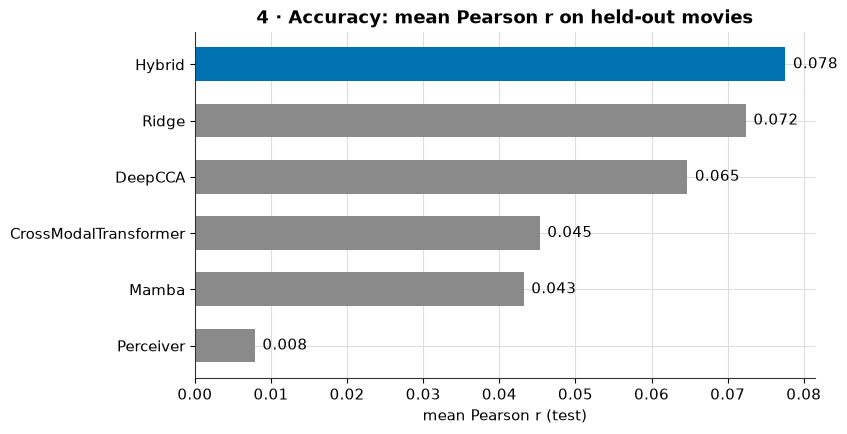

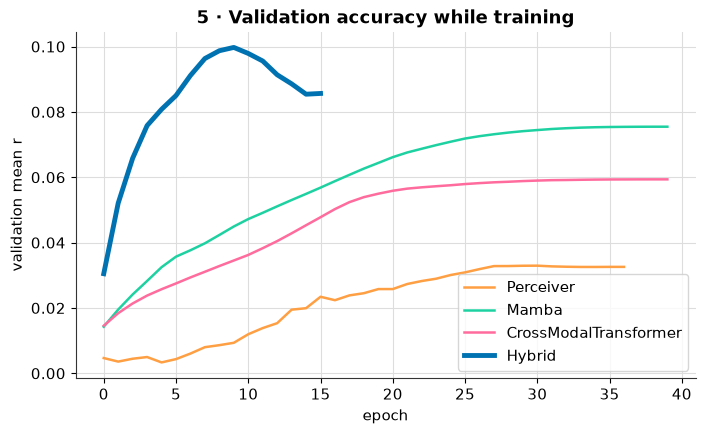

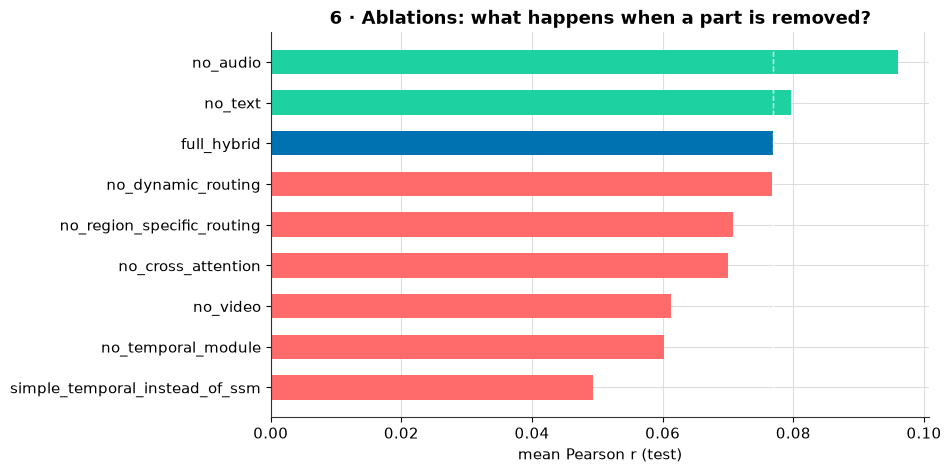

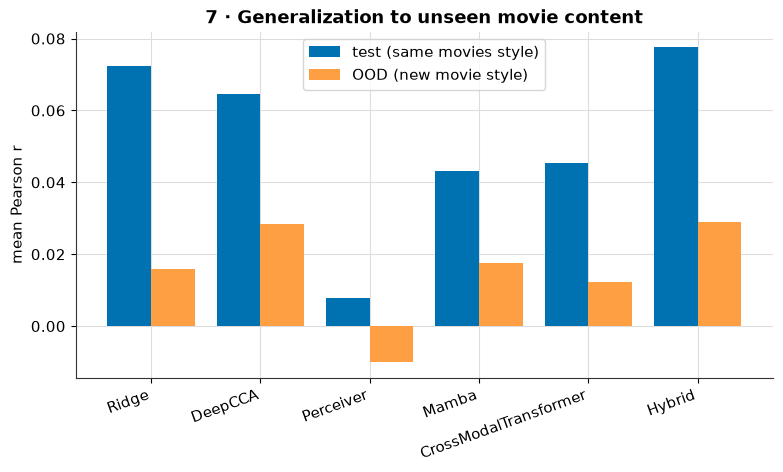

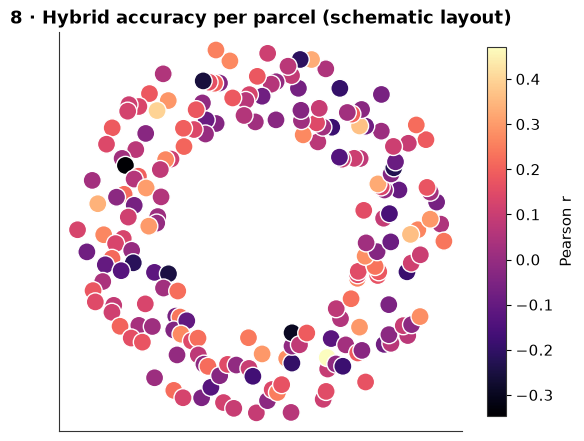

In [16]:
res = pd.DataFrame(rows)

# plot 4: accuracy leaderboard
df = res.sort_values('test_r')
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(df.model, df.test_r, color=[ACC if m == 'Hybrid' else GREY for m in df.model], height=0.6)
for b, v in zip(bars, df.test_r): ax.text(v + 0.001, b.get_y() + b.get_height() / 2, f'{v:.3f}', va='center')
ax.set(title='4 · Accuracy: mean Pearson r on held-out movies', xlabel='mean Pearson r (test)')
plt.show()

# plot 5: validation curves
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, hist), c in zip(histories.items(), ['#ff9f43', '#1dd1a1', '#ff6b9d', ACC]):
    h = pd.DataFrame(hist); ax.plot(h.epoch, h.val_r, color=c, lw=3.5 if name == 'Hybrid' else 1.8, label=name)
ax.set(title='5 · Validation accuracy while training', xlabel='epoch', ylabel='validation mean r'); ax.legend()
plt.show()

# plot 6: ablations
ab = pd.DataFrame(abl).sort_values('test_r'); full = ab[ab.ablation == 'full_hybrid'].test_r.iloc[0]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(ab.ablation, ab.test_r, height=0.6, color=[ACC if a == 'full_hybrid' else ('#1dd1a1' if r > full else '#ff6b6b') for a, r in zip(ab.ablation, ab.test_r)])
ax.axvline(full, color='white', ls='--', lw=1)
ax.set(title='6 · Ablations: what happens when a part is removed?', xlabel='mean Pearson r (test)')
plt.show()

# plot 7: in-distribution vs out-of-distribution
x = np.arange(len(res))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - 0.2, res.test_r, 0.4, color=ACC, label='test (same movies style)'); ax.bar(x + 0.2, res.ood_r, 0.4, color='#ff9f43', label='OOD (new movie style)')
ax.set_xticks(x); ax.set_xticklabels(res.model, rotation=20, ha='right')
ax.set(title='7 · Generalization to unseen movie content', ylabel='mean Pearson r'); ax.legend()
plt.show()

# plot 8: prediction quality per parcel (schematic layout, not real anatomy)
ang = np.linspace(0, 2 * np.pi, P, endpoint=False); rad = 0.55 + 0.45 * np.random.default_rng(7).random(P)
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(rad * np.cos(ang), rad * np.sin(ang), c=pearson(Y['test'], predict(hybrid, 'test')), cmap='magma', s=170, edgecolors='white')
ax.set(title='8 · Hybrid accuracy per parcel (schematic layout)', xticks=[], yticks=[]); ax.set_aspect('equal'); ax.grid(False)
fig.colorbar(sc, shrink=0.8, label='Pearson r')
plt.show()

In [17]:
res.round(4)

,model,params,test_r,test_median_r,test_mse,ood_r,secs
0,Ridge,28800,0.0724,0.0623,0.9803,0.0159,0.0747
1,DeepCCA,26568,0.0647,0.0592,0.9821,0.0284,9.7725
2,Perceiver,216136,0.0079,0.0049,0.9976,-0.0101,21.7085
3,Mamba,95979,0.0432,0.0269,0.9968,0.0175,108.2902
4,CrossModalTransformer,349000,0.0453,0.0376,0.9969,0.0123,38.6886
5,Hybrid,207451,0.0776,0.0888,0.9892,0.0289,113.7455
